### **Student Information**
GitHub ID: AngelinaP

Kaggle name: LISA

Kaggle private scoreboard snapshot:

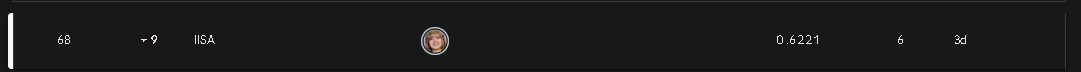

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

---

## 1. Model Development (10 pts Required)

### 1.1 Preprocessing Steps

I joined the raw posts, train/test assignments, and training labels by `post_id`. I checked that the joins were one-to-one, every post had text, the training IDs matched the labeled IDs, and the test IDs matched the sample submission. This gave me 3,360 labeled posts and 1,440 test posts.

For the final models, I lowercased the text, removed links and @mentions, and collapsed repeated whitespace. I kept punctuation because a question mark or repeated exclamation marks can help distinguish how a post is expressed. I also tried lighter cleaning that preserved case and replaced links and mentions with placeholders. In the earlier specialist experiment, the best holdout macro F1 was 0.6536 with lowercasing and removal of URLs and mentions and 0.6364 with light cleaning, so I used this preprocessing for both final submissions.

The training split contained 875 joy, 674 anger, 628 sadness, 454 disgust, 441 surprise, and 288 fear posts. Joy was about three times as frequent as fear. I used stratified splits to keep these proportions similar and macro F1 to give each emotion equal weight when comparing models.

### 1.2 Feature Engineering Steps

For the linear SVM, I combined two TF-IDF representations. Word unigrams captured individual words, punctuation, and single-character tokens. Character sequences of two to five characters within word boundaries captured patterns shared by spelling variants. I kept character features appearing in at least two training documents and used sublinear term frequency so that repeating a term had diminishing influence. Each validation split fitted its own TF-IDF vocabulary on its training portion.

For the two transformers, I used each model’s tokenizer, padded examples within batches of 16, and truncated inputs to 128 tokens. These models learned contextual features during fine-tuning. Before blending, I aligned all score columns to the same six-emotion order and selected only the six competition labels from the specialist.

### 1.3 Explanation of Your Model

The **specialist-only** submission used `j-hartmann/emotion-english-distilroberta-base`, a model already trained to recognize emotions. I fine-tuned it for two epochs with AdamW and a learning rate of 0.00001.

The **blend** combined three sets of scores: 50% from the specialist after **one epoch**, 25% from `FacebookAI/roberta-base` after three epochs at a learning rate of 0.00002, and 25% from a class-balanced linear SVM with C = 0.1. I applied softmax to the SVM decision scores, averaged the three outputs with these weights, and selected the emotion with the highest combined score. Thus the two submissions differed in both model composition and the specialist epoch used.

I first evaluated on a stratified 80/20 split with seed 42. I then compared the fixed settings using three stratified folds with seed 123. Each post received one prediction from models trained on the other two folds. I pooled all 3,360 held-out predictions to calculate one macro F1 per method. Finally, I refitted each method on all labeled posts and exported predictions in sample-submission order.

| Method | Original holdout (672 posts) | Pooled three-fold | Kaggle public | Kaggle private |
|---|---:|---:|---:|---:|
| Specialist only | 0.6536 | 0.6086 | **0.6218** | 0.6086 |
| Blend | **0.6669** | **0.6186** | 0.6056 | **0.6221** |

The specialist led on the public leaderboard, but the blend finished **68th with a private macro F1 of 0.6221**, exceeding the 0.5 baseline. The blend improved private macro F1 by 0.0135 and also performed better in all three local folds. My original holdout was used to choose settings, so its 0.6669 score was optimistic compared with the pooled and private results. Disgust remained difficult for both methods: its pooled F1 rounded to 0.46 for each, compared with 0.75 for joy.

**Learning across epochs.** On the original holdout, the specialist scored 0.6029 before any competition fine-tuning, 0.6450 after one epoch, and 0.6536 after two. The first epoch accounted for most of the improvement. The 0.6669 blend used the one-epoch specialist together with the SVM and general RoBERTa. The general RoBERTa checkpoint supplied pretrained language representations and initialized a new classification head, which the three training epochs fitted to the six labels.

**Cross-validation results (macro F1)**

| Evaluation | Training posts per fit | Held-out posts | Specialist only | Blend |
|---|---:|---:|---:|---:|
| Original holdout | 2,688 | 672 | 0.6536 | 0.6669 |
| Fold 1 | 2,240 | 1,120 | 0.5952 | 0.6079 |
| Fold 2 | 2,240 | 1,120 | 0.6245 | 0.6352 |
| Fold 3 | 2,240 | 1,120 | 0.6026 | 0.6114 |
| All out-of-fold predictions | — | 3,360 | 0.6086 | 0.6186 |

Each fold trained fresh models. I put each prediction back in its original row before calculating pooled F1. This gives one score across all held-out posts. Each fold also had fewer training examples than the original holdout, so both the training size and the choice of validation posts differed.

**Which emotions benefited from blending?** Precision is the fraction of predictions for an emotion that were correct. Recall is the fraction of posts with that true emotion that the model found. F1 combines the two. The values below use the pooled out-of-fold predictions.

| Emotion | Posts | Specialist precision / recall / F1 | Blend precision / recall / F1 |
|---|---:|---:|---:|
| Anger | 674 | 0.53 / 0.64 / 0.58 | 0.54 / 0.67 / 0.60 |
| Disgust | 454 | 0.56 / 0.39 / 0.46 | 0.57 / 0.38 / 0.46 |
| Fear | 288 | 0.68 / 0.62 / 0.65 | 0.70 / 0.62 / 0.66 |
| Joy | 875 | 0.72 / 0.77 / 0.75 | 0.72 / 0.78 / 0.75 |
| Sadness | 628 | 0.63 / 0.59 / 0.61 | 0.62 / 0.64 / 0.63 |
| Surprise | 441 | 0.60 / 0.61 / 0.60 | 0.67 / 0.58 / 0.62 |

For sadness, blending increased recall from 0.59 to 0.64. Surprise showed a different trade-off: the blend’s surprise predictions were more precise, although it missed a larger fraction of actual surprise posts. Disgust had the lowest recall in both methods. Overall accuracy rose from 0.63 to 0.64, while pooled macro F1 improved by 0.0100.

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

I used ChatGPT to help implement the training notebook, interpret validation output, and prepare this report. The table groups repeated follow-ups by purpose and includes examples of my prompts.

| Prompt or follow-up | What I used and why |
|---|---|
| “please make me ipynb file to train this in my laptop” and “or google colab” | I used a Colab GPU for transformer fine-tuning and retained the course notebook format. |
| "Implement lowercasing, URL and @mention removal, and whitespace normalization while retaining punctuation. Compare this with light cleaning." | I chose these steps to reduce variation from usernames and URLs while keeping cues like repeated exclamation marks. The specialist scored 0.6536 with these steps and 0.6364 with light cleaning. |
| “what is svm” and “what is roberta finetuning” | I used a word-and-character TF-IDF SVM as a lexical model and fine-tuned RoBERTa to learn contextual patterns. |
| “recommend me best method to achireve 0,67” and “please make the notebook compare if it only use specialist only” | I tested an emotion-pretrained model both alone and in a weighted blend. I treated 0.67 as a target and reported the measured scores. |
| “explain how do you do three fold local validation” | I compared the fixed methods on identical folds to see how well the original holdout result held up. |
| “here i wanna save the blend as well please” | I exported both methods separately so I could compare their public and private results. I checked the CSV header, ID order, row count and predicted labels. |
| “Mistral + Gemma 2 + Phi-4 ensemble, please also try this” and “make this train until the value decrease” | I explored larger instruction-tuned models separately. The standalone Mistral run fell from 0.5588 at epoch 1 to 0.1020 at epoch 2. My two final submissions came from the specialist comparison above. |

---


**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [ ]:
from pathlib import Path
import re
import html
import zipfile
import pandas as pd
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score
from sklearn.svm import LinearSVC

archive = Path("2026-dm-lab-2-private-competition.zip")
try:
    from google.colab import files
except ImportError:
    files = None

# Use the existing ZIP first; prompt for an upload only when needed.
if not archive.is_file():
    if files is None:
        raise FileNotFoundError(f"Place {archive.name} in {Path.cwd()} or edit archive above.")
    print("Select the competition ZIP.")
    uploaded = files.upload()
    choices = [Path(name) for name in uploaded if name.lower().endswith(".zip")]
    if len(choices) != 1:
        raise ValueError("Select one competition ZIP.")
    archive = choices[0]

# Read the four files directly and preserve identifiers as strings.
with zipfile.ZipFile(archive) as z:
    posts = pd.read_json(z.open("final_posts.json"), dtype={"post_id": str})
    split = pd.read_csv(z.open("data_identification.csv"), dtype=str)
    labels = pd.read_csv(z.open("emotion.csv"), dtype=str)
    sample = pd.read_csv(z.open("sampleSubmission.csv"), dtype=str)

# Verify membership and one-to-one joins before pairing posts with labels.
assert set(split["set"]) == {"train", "test"}
assert set(posts.post_id) == set(split.post_id)
data = split.merge(posts, on="post_id", validate="one_to_one")
assert data.text.notna().all() and data.text.str.strip().ne("").all()
train_rows = data.loc[data["set"] == "train"]
assert set(train_rows.post_id) == set(labels.post_id)
train = train_rows.merge(labels, on="post_id", validate="one_to_one")
test = data.loc[data["set"] == "test"]
assert set(sample.post_id) == set(test.post_id) and sample.post_id.is_unique
emotions = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]
assert set(train.label) == set(emotions)

# Normalize case and whitespace while preserving punctuation and emoji.
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    return re.sub(r"\s+", " ", text).strip()

train["clean_text"] = train.text.map(clean_text)
print(train.label.value_counts(), "\nTest posts:", len(test))

Select the competition ZIP.


Saving 2026-dm-lab-2-private-competition.zip to 2026-dm-lab-2-private-competition.zip
label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64 
Test posts: 1440


## 2. Feature Engineering Steps

In [ ]:
def make_model(tuned, strength=0.1):
    word = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
    if tuned:
        # Keep punctuation and single-character tokens that can convey emotion.
        word.set_params(ngram_range=(1, 1), token_pattern=r"(?u)\b\w+\b|[^\w\s]")
    # Within-word character fragments capture partial matches across spelling variants.
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5) if tuned else (3, 5),
                           min_df=2, sublinear_tf=True)
    # Join the sparse word and character matrices so one classifier can use both.
    features = FeatureUnion([("words", word), ("characters", char)])
    # Fit TF-IDF on the current training split; balanced weights give rarer labels more influence.
    return Pipeline([("features", features),
                     ("classifier", LinearSVC(C=strength if tuned else 1.0, class_weight="balanced", random_state=42))])

## 3. Model Implementation Steps

In [ ]:
import subprocess, sys
import torch
if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime in Colab and run all cells again.")
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers==4.48.3"])
import gc
import numpy as np
from scipy.special import softmax
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, set_seed

SPECIALIST = "j-hartmann/emotion-english-distilroberta-base"
BASE = "FacebookAI/roberta-base"
RUN_THREE_FOLDS = True  # verify the chosen recipe before the final fit
TARGET = 0.67
def light_clean(text):
    text = re.sub(r"http\S+|www\.\S+", " URL ", html.unescape(text))
    text = re.sub(r"@\w+", " USER ", text)
    return " ".join(text.split())

train = train.reset_index(drop=True)
# Put test rows in submission order before generating any predictions.
test = test.set_index("post_id").loc[sample.post_id].reset_index()
for frame in (train, test):
    frame["master"] = frame.text.map(clean_text)
    frame["light"] = frame.text.map(light_clean)
# Reserve 20% for evaluation and preserve the six-class distribution.
fit, val = train_test_split(train, test_size=.2, stratify=train.label, random_state=42)
def macro(labels, probs):
    return f1_score(labels, np.asarray(emotions)[probs.argmax(axis=1)], average="macro")

# Return evaluation probabilities at each epoch. Epoch 0 uses the initial weights.
def transformer_run(checkpoint, column, training, evaluation, epochs, every_epoch=False):
    set_seed(42)
    specialist = checkpoint == SPECIALIST
    tokenizer = AutoTokenizer.from_pretrained(checkpoint)
    options = {} if specialist else {"num_labels": len(emotions)}
    model = AutoModelForSequenceClassification.from_pretrained(checkpoint, **options).cuda()
    # Match pretrained label names to the competition order; omit the neutral output.
    if specialist:
        label_ids = {name.lower(): int(i) for i, name in model.config.id2label.items()}
        columns = [label_ids[name] for name in emotions]
    else:
        columns = list(range(len(emotions)))
    def loader(frame, training_mode):
        texts = frame[column].tolist()
        # Pad each batch to its longest sequence and cap sequences at 128 tokens.
        def collate(indices):
            tokens = tokenizer([texts[i] for i in indices], padding=True, truncation=True,
                               max_length=128, return_tensors="pt").to("cuda")
            if training_mode:
                targets = torch.tensor([emotions.index(frame.label.iloc[i]) for i in indices],
                                       device="cuda")
            else:
                targets = None
            return tokens, targets
        return DataLoader(range(len(frame)), batch_size=16, shuffle=training_mode, collate_fn=collate)
    batches = loader(training, True)
    evaluate = loader(evaluation, False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5 if specialist else 2e-5,
                                  weight_decay=.01)
    outputs = {}
    for epoch in range(epochs + 1):
        # Epoch zero evaluates the initial checkpoint; subsequent passes update its weights.
        if epoch:
            model.train()
            for tokens, targets in batches:
                # Reset gradients, compute the six-class loss, then clip gradients before updating.
                optimizer.zero_grad(set_to_none=True)
                logits = model(**tokens).logits[:, columns]
                torch.nn.functional.cross_entropy(logits, targets).backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.)
                optimizer.step()
        if every_epoch or epoch == epochs:
            # Disable training-only behavior for reproducible evaluation of this checkpoint.
            model.eval()
            with torch.inference_mode():
                outputs[epoch] = np.vstack([model(**tokens).logits[:, columns].softmax(1).cpu().numpy()
                                            for tokens, _ in evaluate])
            if "label" in evaluation and every_epoch:
                print(checkpoint, column, "epoch", epoch, "macro F1",
                      round(macro(evaluation.label, outputs[epoch]), 4), flush=True)
    del model, optimizer
    gc.collect()
    torch.cuda.empty_cache()
    return outputs

def reference(training, evaluation):
    svm = make_model(True).fit(training.master, training.label)
    order = [list(svm.classes_).index(name) for name in emotions]
    # Convert aligned SVM margins to normalized scores for averaging with RoBERTa.
    svm_prob = softmax(svm.decision_function(evaluation.master)[:, order], axis=1)
    base_prob = transformer_run(BASE, "master", training, evaluation, 3)[3]
    return (svm_prob + base_prob) / 2

# Freeze the settings from the previous experiment. Both methods see identical posts.
def compare_methods(training, evaluation):
    epochs = transformer_run(SPECIALIST, "master", training, evaluation, 2, every_epoch=True)
    # Half the blend comes from the one-epoch specialist; each reference model supplies a quarter.
    ref = reference(training, evaluation)
    return {"specialist_only": epochs[2], "blend": 0.5 * epochs[1] + 0.5 * ref}

def report_scores(stage, labels, predictions):
    scores = {name: macro(labels, probs) for name, probs in predictions.items()}
    print(f"{stage}: specialist {scores['specialist_only']:.4f}, blend {scores['blend']:.4f}, "
          f"specialist minus blend {scores['specialist_only'] - scores['blend']:+.4f}")
    return scores

holdout = compare_methods(fit, val)
report_scores("Original holdout", val.label, holdout)

if RUN_THREE_FOLDS:
    folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)
    oof = {name: np.zeros((len(train), len(emotions))) for name in holdout}
    for fold, (a, b) in enumerate(folds.split(train, train.label), 1):
        preds = compare_methods(train.iloc[a], train.iloc[b])
        for name, probs in preds.items():
            # Write held-out predictions back by original row position to align them with the gold labels.
            oof[name][b] = probs
        report_scores(f"Fold {fold}", train.label.iloc[b], preds)
    report_scores("Pooled three-fold macro F1", train.label, oof)
    for name, probs in oof.items():
        print(name)
        print(classification_report(train.label, np.array(emotions)[probs.argmax(1)],
                                    labels=emotions, zero_division=0))

# Refit the fixed recipes on all labeled posts and predict the unlabeled test split.
predictions = compare_methods(train, test)
for name, probs in predictions.items():
    output = pd.DataFrame({"id": test.post_id, "label": np.asarray(emotions)[probs.argmax(1)]})
    # Verify sample order, row count, unique IDs and allowed labels before exporting.
    assert output.id.tolist() == sample.post_id.tolist() and output.id.is_unique
    assert len(output) == 1440 and output.label.isin(emotions).all()
    filename = f"submission_{name}.csv"
    output.to_csv(filename, index=False)
    print("Saved", filename)
    if files is not None:
        files.download(filename)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (19 outputs left out)

Fold 3: specialist 0.6026, blend 0.6114, specialist minus blend -0.0088
Pooled three-fold macro F1: specialist 0.6086, blend 0.6186, specialist minus blend -0.0100
specialist_only
              precision    recall  f1-score   support

       anger       0.53      0.64      0.58       674
     disgust       0.56      0.39      0.46       454
        fear       0.68      0.62      0.65       288
         joy       0.72      0.77      0.75       875
     sadness       0.63      0.59      0.61       628
    surprise       0.60      0.61      0.60       441

    accuracy                           0.63      3360
   macro avg       0.62      0.60      0.61      3360
weighted avg       0.63      0.63      0.62      3360

blend
              precision    recall  f1-score   support

       anger       0.54      0.67      0.60       674
     disgust       0.57      0.38      0.46       454
        fear       0.70      0.62      0.66       288
         joy       0.72      0.78      0.75       875


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Saved submission_specialist_only.csv


Saved submission_blend.csv
